<a href="https://colab.research.google.com/github/syifaST/simuteh--2330511062-/blob/main/notebook/B2_Citra_Warna.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os, sys
REPO = "https://github.com/syifaST/simuteh--2330511062-.git"

if not os.path.exists("/content/simuteh"):
    !git clone {REPO} /content/simuteh
os.chdir("/content/simuteh")

for f in ["notebook", "hasil", "laporan"]:
    os.makedirs(f, exist_ok=True)

# buat ulang dataset kalau ada folder atau label.csv yang kurang
perlu = ["citra", "bersih", "mask_daun", "mask_bercak"]
if (not all(os.path.exists(f"data/sintetis/{d}") for d in perlu)
        or not os.path.exists("data/sintetis/label.csv")):
    !python src/buat_dataset_sintetis.py

os.chdir("/content/simuteh/notebook")
sys.path.append("../src")

print("Folder kerja:", os.getcwd())
print("Jumlah citra:", len(os.listdir("../data/sintetis/citra")))
print("Jumlah bersih:", len(os.listdir("../data/sintetis/bersih")))
print("Ada label.csv:", os.path.exists("../data/sintetis/label.csv"))
print("Isi src:", os.listdir("../src"))

Cloning into '/content/simuteh'...
remote: Enumerating objects: 418, done.
remote: Counting objects: 100% (8/8), done.
remote: Compressing objects: 100% (7/7), done.
remote: Total 418 (delta 5), reused 1 (delta 1), pack-reused 410 (from 2)
Receiving objects: 100% (418/418), 58.40 MiB | 33.42 MiB/s, done.
Resolving deltas: 100% (97/97), done.
Selesai: 60 citra tersimpan di data/sintetis
Folder kerja: /content/simuteh/notebook
Jumlah citra: 61
Jumlah bersih: 61
Ada label.csv: True
Isi src: ['utils_cv.py', 'praproses.py', 'buat_dataset_sintetis.py']


# **2.3**

In [2]:
import cv2, numpy as np

bercak_rgb = (196, 178, 86)
daun_rgb = (52, 136, 60)
px = np.array([[bercak_rgb[::-1], daun_rgb[::-1]]], dtype=np.uint8)  # ke BGR

gray = cv2.cvtColor(px, cv2.COLOR_BGR2GRAY)
hsv = cv2.cvtColor(px, cv2.COLOR_BGR2HSV)
print("Gray bercak, daun:", gray[0, 0], gray[0, 1],
      "| selisih:", int(gray[0, 0]) - int(gray[0, 1]))
print("Hue bercak, daun:", hsv[0, 0, 0], hsv[0, 1, 0])

Gray bercak, daun: 173 102 | selisih: 71
Hue bercak, daun: 25 63


KB kanal B   : 1.51
KB kanal G   : 1.81
KB kanal R   : 8.99
KB kanal Gray: 5.32
KB kanal H   : 5.66
KB kanal S   : 0.58
KB kanal V   : 3.48


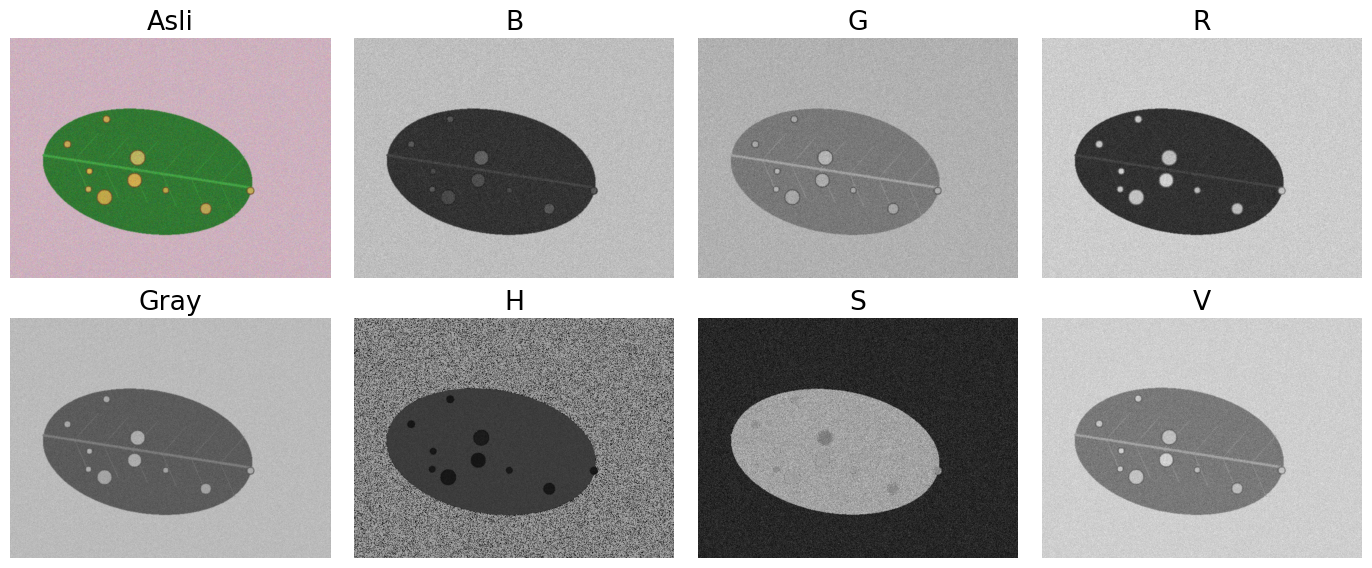

In [14]:
import cv2
from utils_cv import baca, tampil, kontras_bercak
import matplotlib.pyplot as plt

nama = "teh_041.png"                 # kelas berat, kondisi normal
img = baca(f"../data/sintetis/citra/{nama}")
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
b, g, r = cv2.split(img)
h, s, v = cv2.split(hsv)
kanal = {"B": b, "G": g, "R": r, "Gray": gray, "H": h, "S": s, "V": v}

tampil([img] + list(kanal.values()), ["Asli"] + list(kanal.keys()),
       baris=2, ukuran=(14, 6))
for nm, c in kanal.items():
    print(f"KB kanal {nm:4s}: {kontras_bercak(c, md, mb):.2f}")

# **2.4**

fx=0.5: ukuran (240, 320), KB=6.89
fx=0.2: ukuran (96, 128), KB=5.88
fx=0.1: ukuran (48, 64), KB=3.76
fx=0.05: ukuran (24, 32), KB=1.71


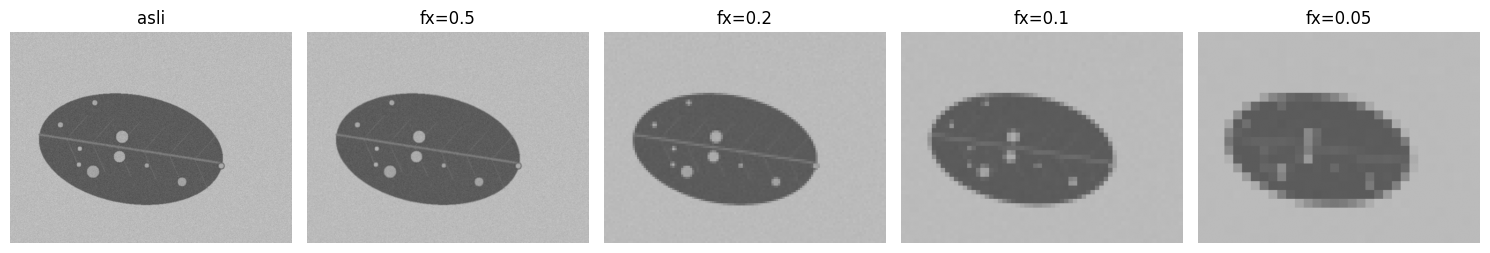

k=1: 2 level, KB=8.54
k=2: 4 level, KB=8.43
k=3: 6 level, KB=3.45
k=4: 11 level, KB=4.80
k=8: 163 level, KB=5.32


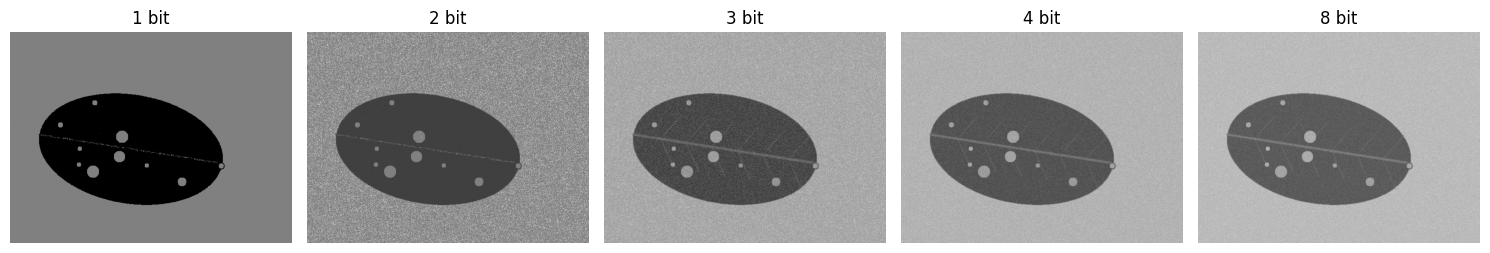

In [8]:
# sampling: perkecil lalu perbesar kembali ke ukuran semula
hasil_sampling = []
for fx in [0.5, 0.2, 0.1, 0.05]:
    kecil = cv2.resize(gray, None, fx=fx, fy=fx, interpolation=cv2.INTER_AREA)
    besar = cv2.resize(kecil, gray.shape[::-1], interpolation=cv2.INTER_NEAREST)
    print(f"fx={fx}: ukuran {kecil.shape}, KB={kontras_bercak(besar, md, mb):.2f}")
    hasil_sampling.append(besar)

tampil([gray] + hasil_sampling,
       ["asli", "fx=0.5", "fx=0.2", "fx=0.1", "fx=0.05"], ukuran=(15, 3))
plt.savefig("../hasil/b2_sampling.png"); plt.show()

# kuantisasi: sisakan k bit
hasil_kuant = []
for k in [1, 2, 3, 4, 8]:
    langkah = 256 // (2 ** k)
    kuant = (gray // langkah) * langkah
    print(f"k={k}: {len(np.unique(kuant))} level, "
          f"KB={kontras_bercak(kuant, md, mb):.2f}")
    hasil_kuant.append(kuant)

tampil(hasil_kuant, [f"{k} bit" for k in [1, 2, 3, 4, 8]], ukuran=(15, 3))
plt.savefig("../hasil/b2_kuantisasi.png"); plt.show()

# **2.5**

In [12]:
import pandas as pd

def semua_kanal(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    b, g, r = cv2.split(img); h, s, v = cv2.split(hsv)
    return {"B": b, "G": g, "R": r,
            "Gray": cv2.cvtColor(img, cv2.COLOR_BGR2GRAY),
            "H": h, "S": s, "V": v}

label = pd.read_csv("../data/sintetis/label.csv")

def hitung_tabel(kelas):
    baris = []
    for _, d in label[label.kelas == kelas].iterrows():
        im = baca(f"../data/sintetis/citra/{d.nama_file}")
        m_d = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)
        m_b = cv2.imread(f"../data/sintetis/mask_bercak/{d.nama_file}", 0)
        kb = {k: kontras_bercak(c, m_d, m_b) for k, c in semua_kanal(im).items()}
        kb["kondisi"] = d.kondisi_cahaya
        baris.append(kb)
    return pd.DataFrame(baris).groupby("kondisi").mean().round(2)

tabel_kb = hitung_tabel("berat")
print(tabel_kb)
tabel_kb.to_csv("../hasil/b2_kb_kanal.csv")

                   B     G      R  Gray     H     S     V
kondisi                                                  
bayangan        1.92  0.77   6.18  2.29  4.73  1.12  1.43
gelap           1.80  1.26  10.78  4.68  6.31  1.09  3.43
kontras_rendah  1.08  0.62   4.52  2.63  2.50  0.31  1.68
normal          1.77  1.06   9.86  4.74  7.49  0.97  2.72
terang          3.03  0.63   8.05  4.13  6.86  1.66  1.97


# **2.6**

                   B     G      R  Gray     H     S     V
kondisi                                                  
bayangan        0.67  0.41   3.99  0.96  4.05  0.61  0.66
gelap           0.92  0.89  10.02  3.90  6.13  0.93  2.50
kontras_rendah  0.54  0.40   3.29  1.45  1.84  0.24  0.90
normal          1.25  0.31   8.18  3.27  6.77  0.97  1.52
terang          1.47  0.42   5.23  2.48  4.13  0.69  1.26
Sama dengan kelas berat? False
teh_021.png {'B': np.float64(1.1), 'G': np.float64(0.08), 'R': np.float64(8.24), 'Gray': np.float64(3.2), 'H': np.float64(6.91), 'S': np.float64(0.88), 'V': np.float64(1.6)} -> terbaik: R


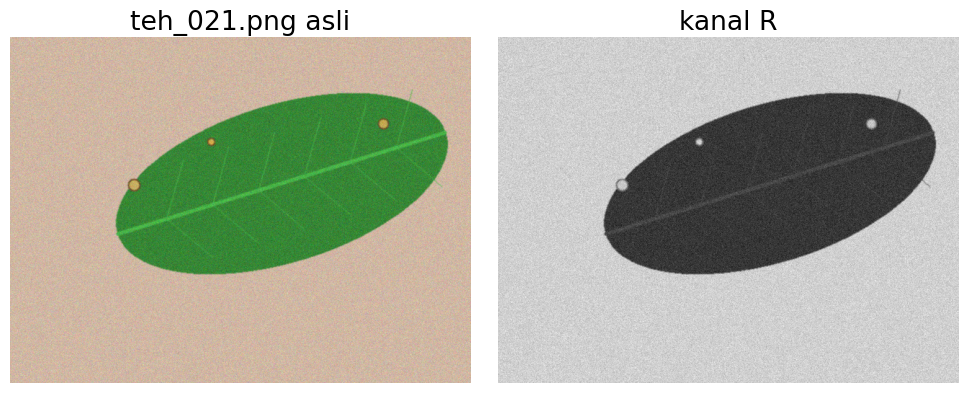

teh_045.png {'B': np.float64(0.84), 'G': np.float64(0.05), 'R': np.float64(4.43), 'Gray': np.float64(1.21), 'H': np.float64(3.46), 'S': np.float64(1.04), 'V': np.float64(0.49)} -> terbaik: R


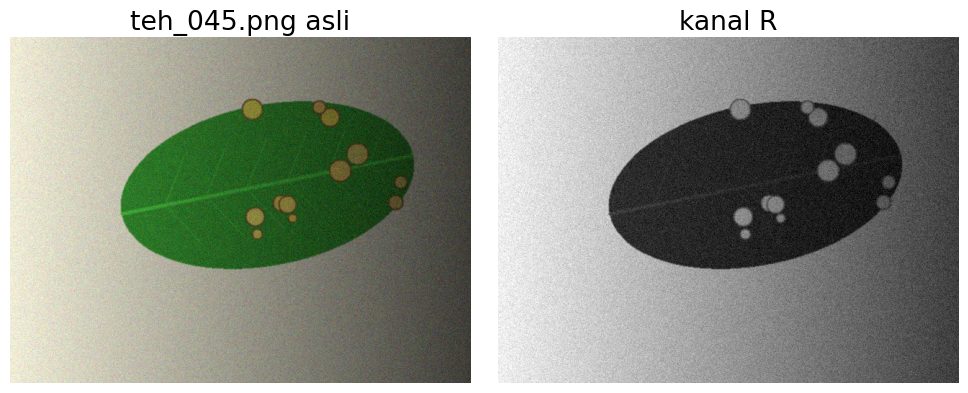

In [13]:
tabel_kb_ringan = hitung_tabel("ringan")
print(tabel_kb_ringan)
print("Sama dengan kelas berat?", tabel_kb_ringan.equals(tabel_kb))  # harus False
tabel_kb_ringan.to_csv("../hasil/b2_kb_kanal_ringan.csv")

for nama in ["teh_021.png", "teh_045.png"]:
    im = baca(f"../data/sintetis/citra/{nama}")
    m_d = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    m_b = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    kanal_im = semua_kanal(im)
    kb = {k: kontras_bercak(c, m_d, m_b) for k, c in kanal_im.items()}
    terbaik = max(kb, key=kb.get)
    print(nama, {k: round(v, 2) for k, v in kb.items()}, "-> terbaik:", terbaik)
    tampil([im, kanal_im[terbaik]], [f"{nama} asli", f"kanal {terbaik}"],
           ukuran=(10, 4))
    plt.savefig(f"../hasil/b2_terbaik_{nama[:-4]}.png")
    plt.show()

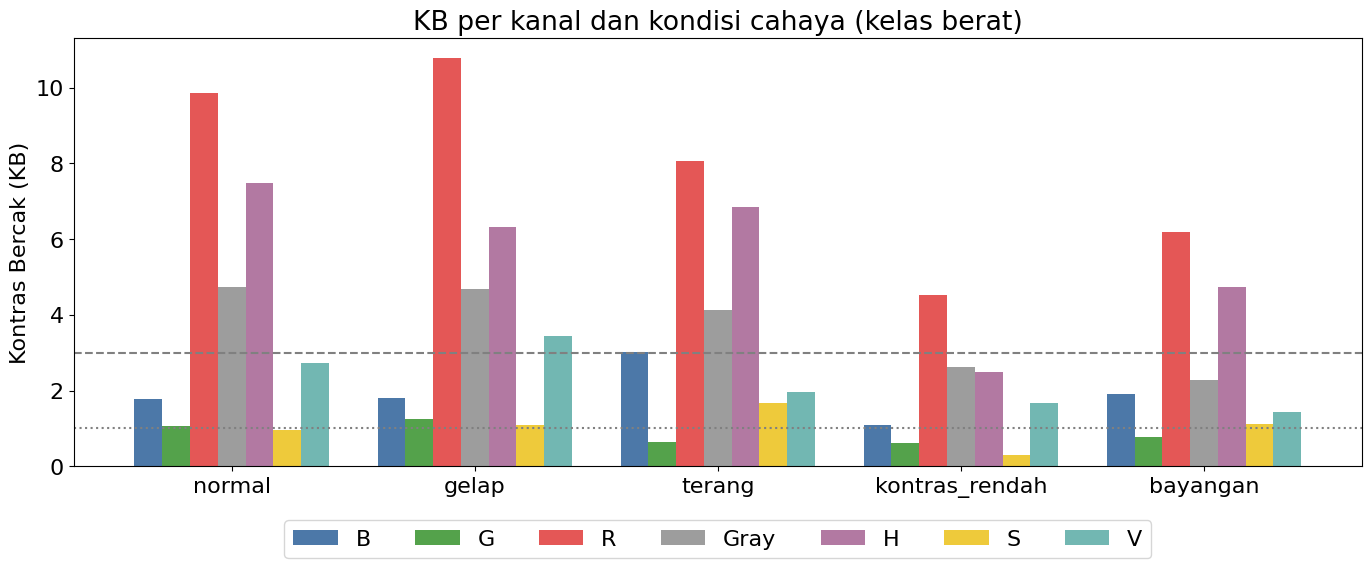

In [9]:
plt.rcParams.update({"font.size": 16})
urut = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]
warna = ["#4c78a8", "#54a24b", "#e45756", "#9d9d9d", "#b279a2", "#eeca3b", "#72b7b2"]  # B G R Gray H S V

ax = tabel_kb.loc[urut].plot(kind="bar", figsize=(14, 6), width=0.8, color=warna)
ax.axhline(3, ls="--", c="gray"); ax.axhline(1, ls=":", c="gray")   # patokan KB 3 dan 1
ax.set_ylabel("Kontras Bercak (KB)"); ax.set_xlabel("")
ax.set_title("KB per kanal dan kondisi cahaya (kelas berat)")
plt.xticks(rotation=0)
plt.legend(ncol=7, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.tight_layout()
plt.savefig("../hasil/b2_grafik_kb_kanal.png", dpi=200)
plt.show()